# Method A: editing instructions applied by FLUX.1 Kontext

| step |  | 
|---|---|
| 1–3 | install, paths, API key | 
| 4 | read the prompts that will be sent | 
| 5 | one request, to test the key |
| 6 | all requests: photographs × 3 versions × 4 seeds |
| 7 | ResMem scores, contact sheet, `review.csv` |
| 8 | ViTMem scores |
| 9 | review pages | 
| 10 | human check: fill in `review.csv` | 
| 11 | choose one edited image per photograph | 
| 12 | export the stimulus pairs |
| 13 | statistics |

## 1. Install

In [9]:
import sys
!"{sys.executable}" -m pip install -r scripts/requirements.txt

## 2. Paths

`PHOTO_FOLDER` is the folder with the original photographs.

In [10]:
import os, glob, csv, json
from IPython.display import Image as Show

PHOTO_FOLDER = '../data/development_photos'      # change to your folder of the original photographs
OUT = 'results_method_a'

have = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(os.path.join(PHOTO_FOLDER, '**', '*.jpg'), recursive=True)}
want = {r['photo'] for r in csv.DictReader(open('../data/instructions.csv', encoding='utf-8'))}
print('photos with instructions:', len(have & want), 'of', len(want))
print('missing from folder:', sorted(want - have))

photos with instructions: 20 of 20
missing from folder: []


## 3. API key

Paste the key when asked. It is kept in memory only, not saved in the notebook.

In [11]:
import getpass
os.environ['BFL_API_KEY'] = getpass.getpass('BFL API key: ')
print('key set:', len(os.environ['BFL_API_KEY']) > 10)

key set: True


## 4. The prompts that will be sent 

In [13]:
!"{sys.executable}" scripts/generate_a.py "{PHOTO_FOLDER}" --out {OUT} --dry-run

JQtFVermbRWkDYNXsJVGhA A_guided: 'Remove the dark folded napkin on the left. Sharpen the bacon, the melted cheese, the lettuce and the tomato. Keep the same framing, camera angle, light and colours as the original, with the plate of tomato at the bottom left, the loose piece of bacon on the board and the glass of iced drink at the right edge exactly where they are. Keep the food itself exactly the same: the same dish, the same ingredients, the same portion and arrangement. Do not add any new objects, garnish or text.'

JQtFVermbRWkDYNXsJVGhA A_study1: 'Remove the non-food objects around the dish, such as cutlery, napkins, phones, bags and packaging, so that fewer objects are in the photograph, and make the whole photograph brighter. Keep the same framing and camera angle. Keep the food itself exactly the same: the same dish, the same ingredients, the same portion and arrangement. Do not add any new objects, garnish or text.'

JQtFVermbRWkDYNXsJVGhA A_empty: ' '

iiB5a_883CdFWv3q2j9EgQ 

## 5. One request, to test the key

One photograph, one seed. 

In [14]:
!"{sys.executable}" scripts/generate_a.py "{PHOTO_FOLDER}" --out {OUT} --limit 1 --arms A_guided --seeds 0

1 requests; 0 already done; 1 to send to flux-kontext-pro with 3 in parallel
[1/1] JQtFVermbRWkDYNXsJVGhA__A_guided_s0.png  ok 8.6s

1 generated, 0 failed -> results_method_a/for_scoring


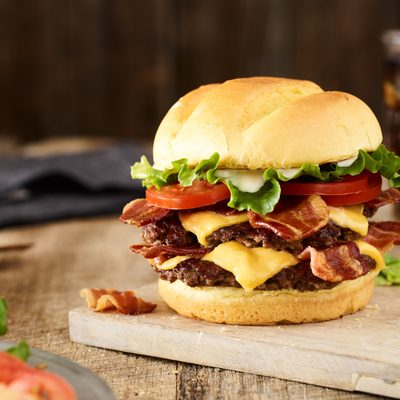

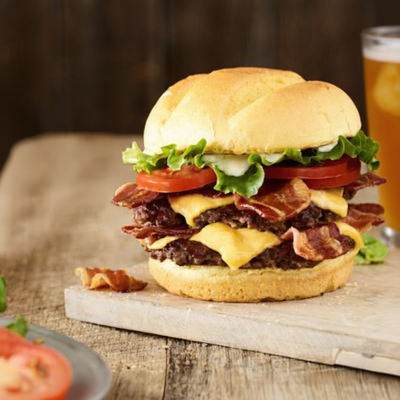

In [15]:
f = sorted(glob.glob(f'{OUT}/for_scoring/*A_guided_s0.png'))[0]
pid = os.path.basename(f).split('__')[0]
orig = glob.glob(os.path.join(PHOTO_FOLDER, '**', pid + '.jpg'), recursive=True)[0]
display(Show(orig, width=400), Show(f, width=400))

## 6. All requests

If it stops or some requests fail, run the cell again: finished requests are skipped.

In [44]:
!"{sys.executable}" scripts/generate_a.py "{PHOTO_FOLDER}" --out {OUT}

240 requests; 160 already done; 80 to send to flux-kontext-pro with 3 in parallel
[1/80] JQtFVermbRWkDYNXsJVGhA__A_study1_s1.png  ok 8.1s
[2/80] JQtFVermbRWkDYNXsJVGhA__A_study1_s2.png  ok 10.2s
[3/80] JQtFVermbRWkDYNXsJVGhA__A_study1_s0.png  ok 14.2s
[4/80] JQtFVermbRWkDYNXsJVGhA__A_study1_s3.png  ok 6.2s
[5/80] iiB5a_883CdFWv3q2j9EgQ__A_study1_s0.png  ok 5.2s
[6/80] iiB5a_883CdFWv3q2j9EgQ__A_study1_s2.png  ok 5.1s
[7/80] iiB5a_883CdFWv3q2j9EgQ__A_study1_s1.png  ok 5.7s
[8/80] iiB5a_883CdFWv3q2j9EgQ__A_study1_s3.png  ok 5.5s
[9/80] FzdbrnTID0spvbDQUarO9w__A_study1_s0.png  ok 5.3s
[10/80] FzdbrnTID0spvbDQUarO9w__A_study1_s1.png  ok 5.1s
[11/80] FzdbrnTID0spvbDQUarO9w__A_study1_s2.png  ok 6.1s
[12/80] FzdbrnTID0spvbDQUarO9w__A_study1_s3.png  ok 5.2s
[13/80] j4a5-Hlj3H6JiIaRlXc3yQ__A_study1_s0.png  ok 5.3s
[14/80] j4a5-Hlj3H6JiIaRlXc3yQ__A_study1_s1.png  ok 7.8s
[15/80] j4a5-Hlj3H6JiIaRlXc3yQ__A_study1_s2.png  ok 5.4s
[16/80] j4a5-Hlj3H6JiIaRlXc3yQ__A_study1_s3.png  ok 5.5s
[17/80] KBuEA

## 7. ResMem, contact sheet, review sheet

In [45]:
!"{sys.executable}" scripts/score_a.py "{PHOTO_FOLDER}" --out {OUT}

loading ResMem ...
[1/20] 1P4J68Ao1BgqrIaID-B_eg: original 0.838  A_guided +0.020  A_empty +0.022
[2/20] 2Q7GC3XGDZLqs2giZK3ukA: original 0.771  A_guided +0.033  A_empty +0.064
[3/20] 474Icdf-IkpX8131Ra0x-A: original 0.760  A_guided -0.029  A_empty +0.006
[4/20] FzdbrnTID0spvbDQUarO9w: original 0.747  A_guided +0.070  A_empty +0.083
[5/20] GbnseqqexlHCFYtra-4bKA: original 0.733  A_guided +0.006  A_empty +0.005
[6/20] JQtFVermbRWkDYNXsJVGhA: original 0.718  A_guided +0.065  A_empty +0.082
[7/20] KBuEAp0bzcETW6RhI0fcNg: original 0.925  A_guided +0.004  A_empty +0.004
[8/20] OOWgYWNn5upAHbDHWKSyCw: original 0.793  A_guided +0.109  A_empty +0.118
[9/20] QpzgQi79OKNB9zQXRPuP5w: original 0.683  A_guided +0.083  A_empty +0.067
[10/20] U9tmSzPMSJFNH6p9RCPcYA: original 0.802  A_guided -0.029  A_empty -0.006
[11/20] YEsPOcFAWPGtCKbUvSsHMA: original 0.689  A_guided +0.087  A_empty +0.098
[12/20] aofLqa8kNqApRR5MVl2UkQ: original 0.835  A_guided +0.033  A_empty -0.014
[13/20] f7xG76_Iy1OuQ68yzE22Zw

c:\Users\59784\anaconda3\envs\psypher\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\59784\anaconda3\envs\psypher\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


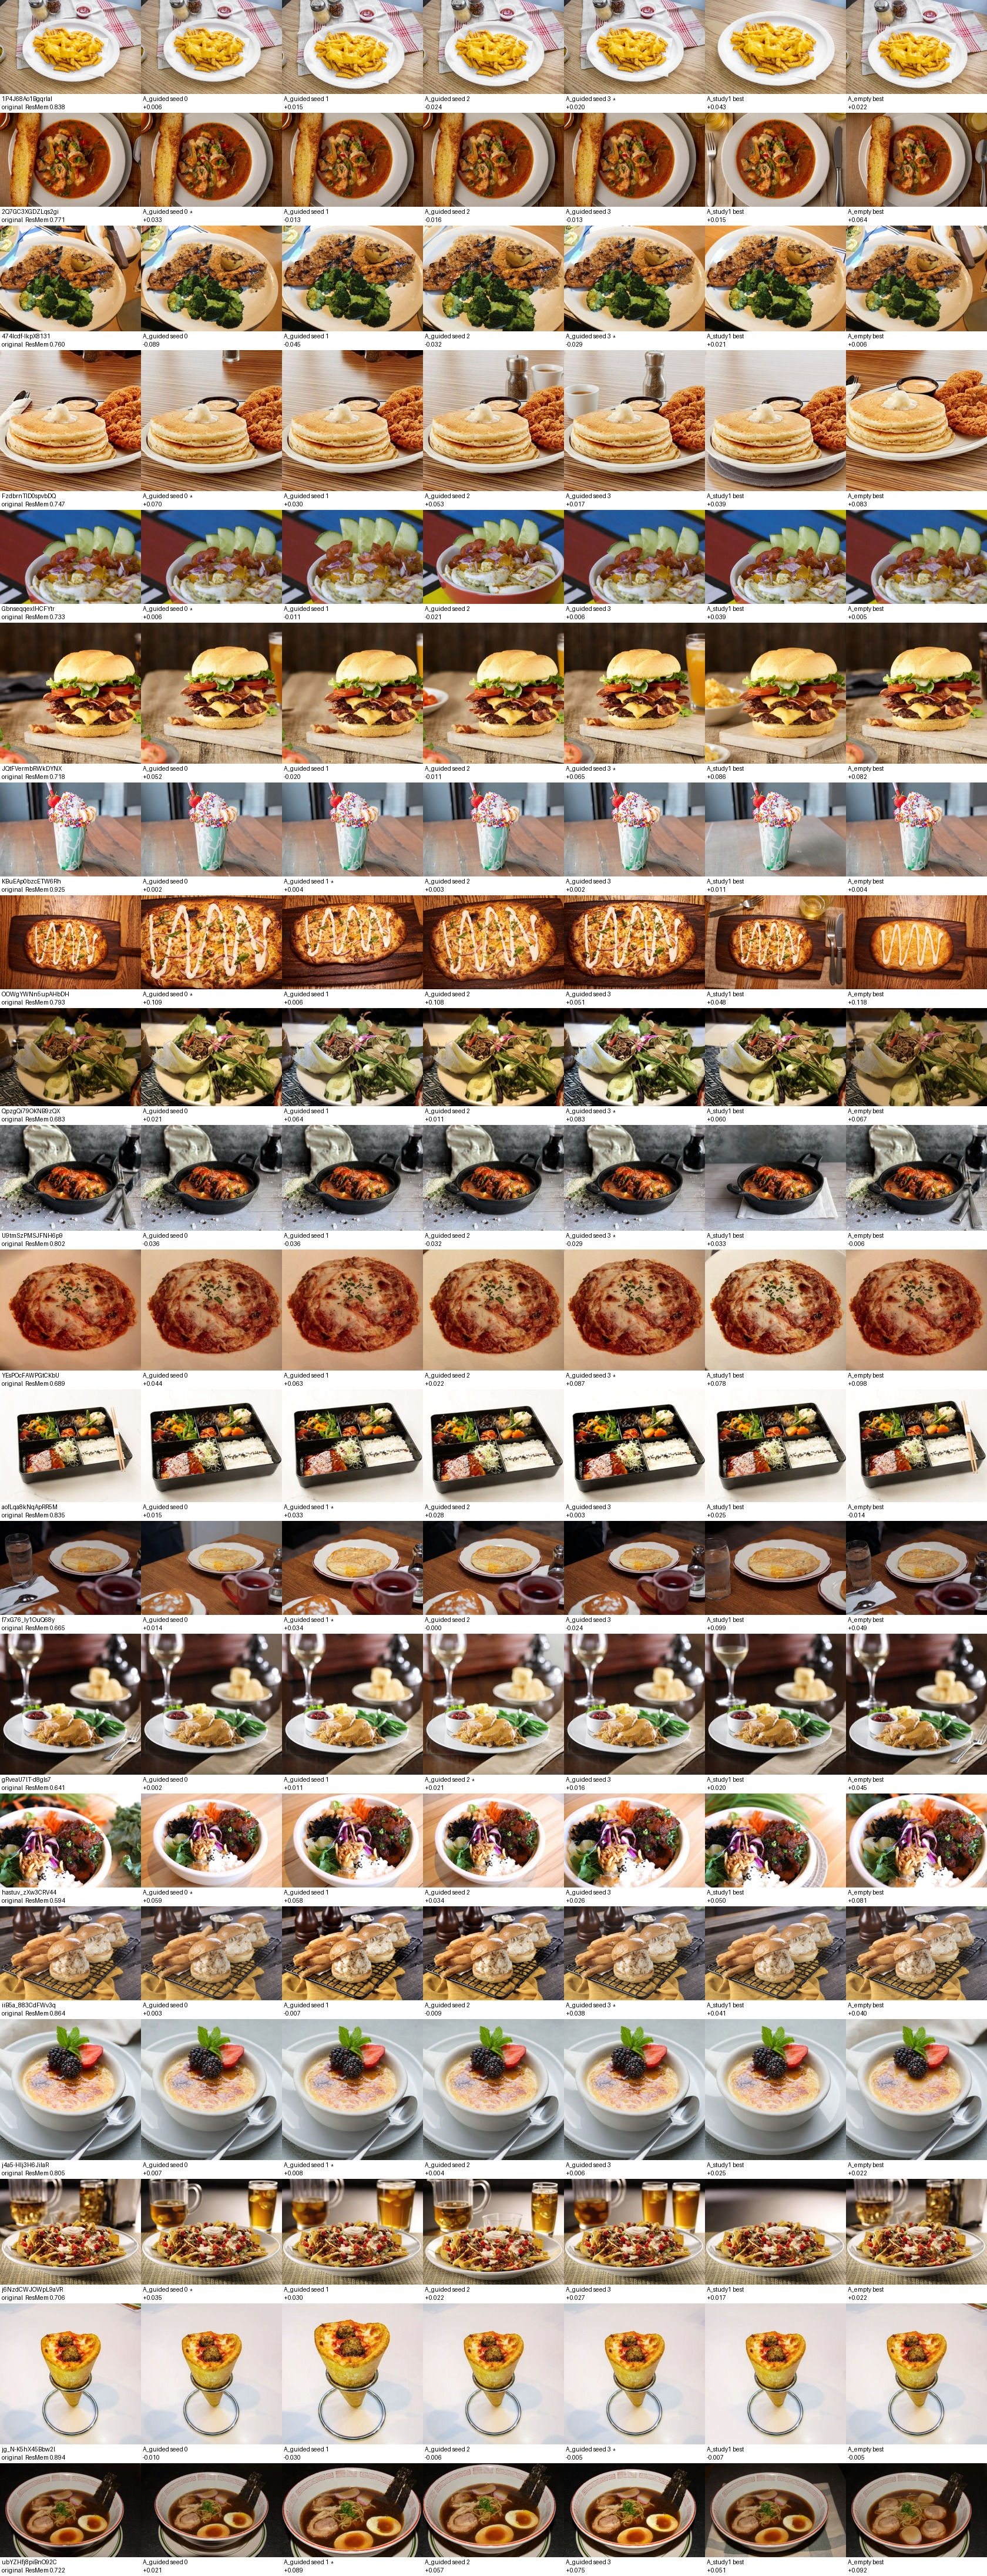

In [46]:
Show(f'{OUT}/contact_sheet.jpg')

## 8. Second model: ViTMem

ResMem chose the best seed, so its gain is inflated by the choosing. ViTMem score is  used for comparison.

In [47]:
!"{sys.executable}" scripts/score_vitmem.py {OUT}

  50/260
  100/260
  150/260
  200/260
  250/260
  260/260
wrote results_method_a\vitmem_scores.csv (260 images)


In [48]:
!"{sys.executable}" scripts/merge_scores.py {OUT} {OUT}/vitmem_scores.csv --name vitmem

merged 260 of 260 candidates into results_method_a\candidates.csv

mean change from the original   (ResMem chose; ViTMem is the independent check)
  A_guided best of seeds     n=20  ResMem +0.036   ViTMem +0.012   ViTMem>0 in 75%
  A_study1 best of seeds     n=20  ResMem +0.040   ViTMem +0.012   ViTMem>0 in 75%
  A_empty best of seeds      n=20  ResMem +0.044   ViTMem +0.006   ViTMem>0 in 65%

paired, same photographs, ViTMem
  A_guided - A_empty   mean +0.0059   A_guided better in 13 of 20
  A_study1 - A_empty   mean +0.0061   A_study1 better in 14 of 20
  A_guided - A_study1   mean -0.0002   A_guided better in 8 of 20

ResMem vs ViTMem change, all candidates: r = 0.19  (low r means the two models disagree on what an edit does)


## 9. Review pages

One page per photograph: the original and its twelve edited images, in `results_method_a/review_sheets/`.
Notes already written in `review.csv` appear in red on the pages.

In [49]:
!"{sys.executable}" scripts/review_sheets.py --out {OUT}
print('pages in', f'{OUT}/review_sheets')

20 pages -> results_method_a\review_sheets
pages in results_method_a/review_sheets


## 10. Human check: fill in `review.csv`

Open `results_method_a/review.csv`. On the review sheets, compare each edited image with its
original. To reject an edited image, put `1` in `reject` and a reason, e.g. `dish_changed`, `ingredients_changed`,
`portion_changed`, `object_or_text_added`, `visible_artifact`, `not_a_credible_photo`. Leave `reject` empty to
keep it. Save as CSV (not xlsx).

## 11. Choose one image per photograph

Among the edited images not rejected, we select the image with highest ResMem score. Run again after any change to `review.csv`.

In [55]:
!"{sys.executable}" scripts/select_a.py --out {OUT}

37 candidates rejected in review.csv
  A_guided  chosen for 20 photographs   ResMem +0.036   ViTMem +0.012   ViTMem>0 in 75%
  A_study1  chosen for 16 photographs   ResMem +0.034   ViTMem +0.012   ViTMem>0 in 75%
  A_empty   chosen for 20 photographs   ResMem +0.036   ViTMem +0.004   ViTMem>0 in 60%
-> results_method_a/final_selection.csv, final/, final_sheet.jpg


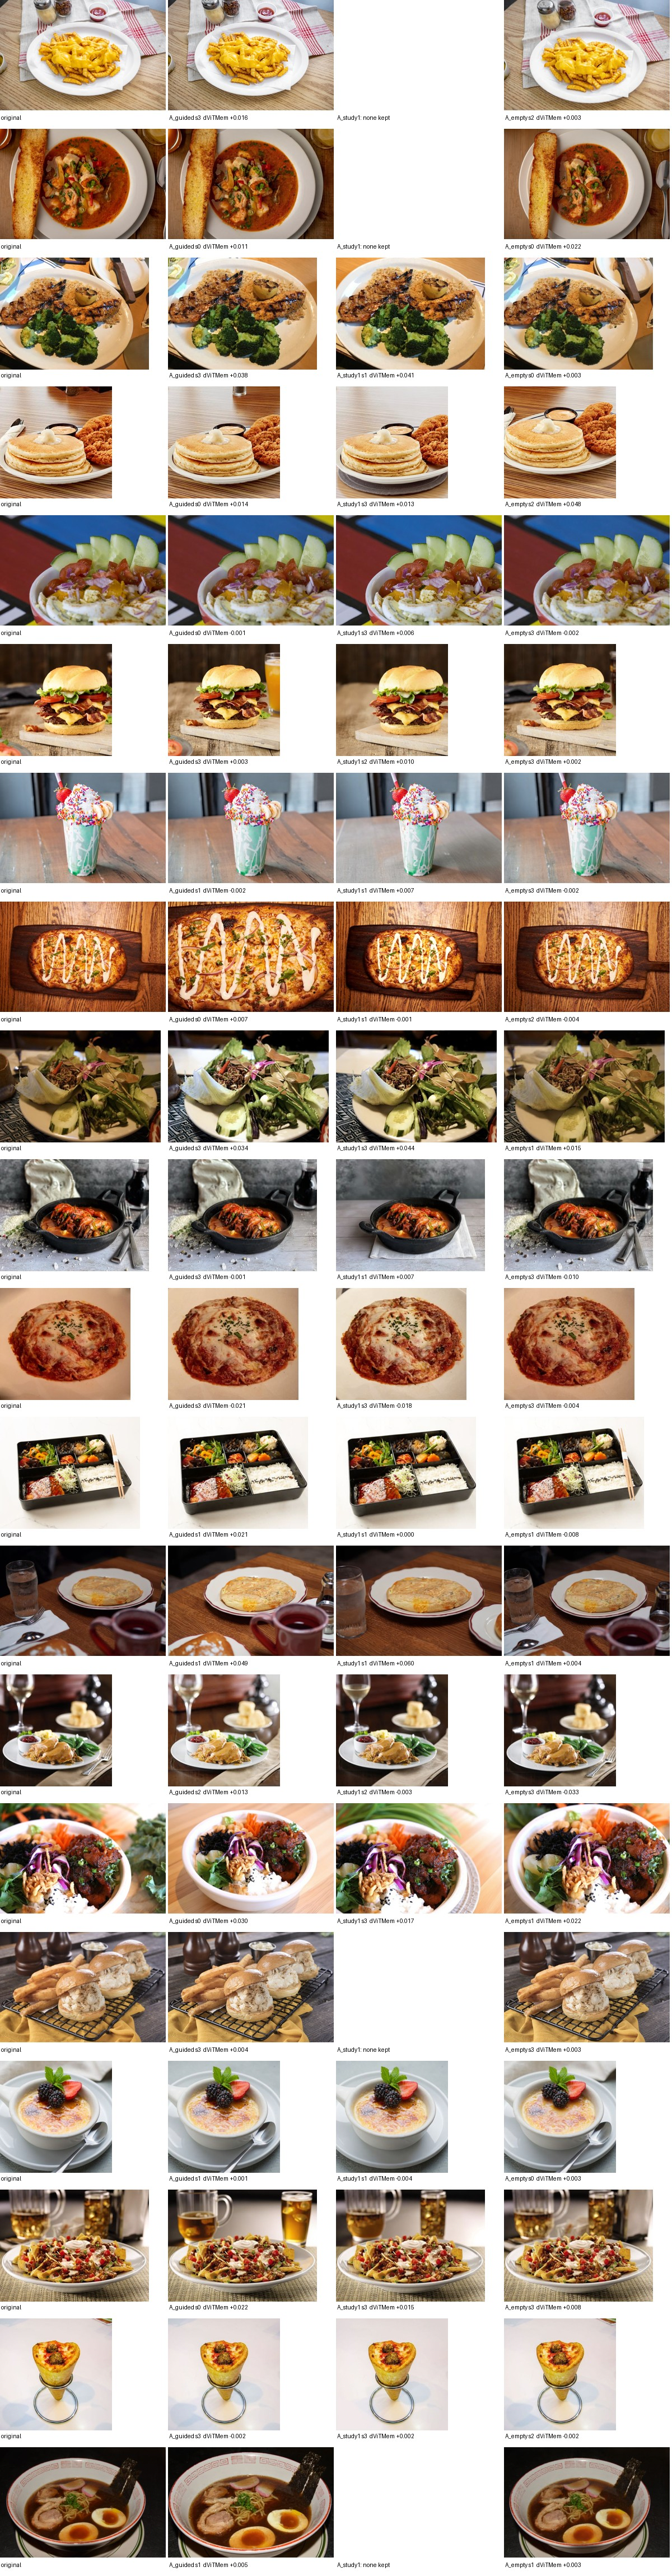

In [56]:
Show(f'{OUT}/final_sheet.jpg')

## 12. Export the stimulus pairs

Original and edited image of each photograph, processed identically: taken at the size they were scored at and saved as PNG.
Output: `results_method_a/stimuli/<category>/<photo>_original.png` and `_edited.png`, plus `stimuli.csv`.

`HEIGHT = None` keeps the native size (no resampling). Set e.g. `HEIGHT = 800` to enlarge both; then
`--rescore` checks that the scores did not change.

In [57]:
HEIGHT = None          # e.g. 800 to enlarge both versions to 800 px high

if HEIGHT:
    !"{sys.executable}" scripts/export_stimuli.py --out {OUT} --height {HEIGHT} --rescore
else:
    !"{sys.executable}" scripts/export_stimuli.py --out {OUT}

20 pairs -> results_method_a\stimuli/  (native size, unchanged, PNG)


## 13. Statistics

For each version, the chosen edited image (after the human check) is compared with its original:
paired t-test, 95% confidence interval, and Wilcoxon test as a
robustness check. Then the versions are compared with each other on the same photographs.
**Compare on ViTMem**: ResMem chose the best seed, so its changes are inflated.

In [59]:
import pandas as pd, numpy as np
from scipy import stats

sel = pd.read_csv(f'{OUT}/final_selection.csv')
arms = [a for a in ('A_guided', 'A_study1', 'A_empty') if a in set(sel.method)]
scores = [s for s in ('d_vitmem', 'd_resmem') if s in sel]
if 'd_vitmem' not in sel:
    print('No ViTMem scores in final_selection.csv: run step 8, then step 11, then this cell.')

def test(d):
    d = np.asarray(d, float); d = d[~np.isnan(d)]
    m, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    lo, hi = stats.t.interval(0.95, len(d) - 1, loc=m, scale=se)
    return dict(n=len(d), mean=m, ci_low=lo, ci_high=hi, pct_up=(d > 0).mean(),
                p_t=stats.ttest_1samp(d, 0).pvalue, p_wilcoxon=stats.wilcoxon(d).pvalue)

for score in scores:
    res = pd.DataFrame({a: test(sel.loc[sel.method == a, score]) for a in arms}).T
    print(f'\n=== {score}: change from the original (edited - original), test against 0 ===')
    print('    (the chosen edited image per photograph, after the human check; ResMem is inflated by the choosing)')
    print(res.astype(float).round(4).to_string())

# versions compared with each other, same photographs
wide = sel.pivot(index='photo', columns='method', values=scores)
for score in scores:
    for a, b in [('A_guided', 'A_empty'), ('A_study1', 'A_empty'), ('A_guided', 'A_study1')]:
        if {a, b} <= set(arms):
            diff = (wide[(score, a)] - wide[(score, b)]).dropna()
            r = test(diff)
            print(f"\n{a} - {b} ({score}): mean {r['mean']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}], "
                  f"p (t) = {r['p_t']:.3g}, p (Wilcoxon) = {r['p_wilcoxon']:.3g}, n = {r['n']}")
            
# before the human check: best ResMem version per photograph, ignoring review.csv
cand = pd.read_csv(f'{OUT}/candidates.csv')
cand = cand[cand.method.isin(arms)]
sel_before = cand.loc[cand.groupby(['photo', 'method'])['resmem'].idxmax()]
for score in scores:
    res = pd.DataFrame({a: test(sel_before.loc[sel_before.method == a, score]) for a in arms}).T
    print(f'\n=== BEFORE the human check: {score} ===')
    print(res.astype(float).round(4).to_string())

# share of versions rejected in the human check, per arm
review = pd.read_csv(f'{OUT}/review.csv', dtype=str).fillna('')
review['arm'] = review.file.str.extract(r'__(A_[A-Za-z0-9]+)_s\d+\.png')[0]
review['rejected'] = review.reject.str.strip().str.lower().isin(['1', '1.0', 'yes', 'y', 'x', 'true'])
print('\nrejected versions per arm:')
print(review.groupby('arm').rejected.agg(['sum', 'count', 'mean']).round(2).to_string())

# correlation between ResMem and ViTMem changes, versions that passed the human check
rejected = set(review.loc[review.rejected, 'file'])
ok = cand[~cand.file.isin(rejected)]
print('\nResMem vs ViTMem change, versions that passed the human check:')
print('  Method A: n = %d, r = %.2f' % (len(ok), ok[['d_resmem', 'd_vitmem']].corr().iloc[0, 1]))
for a, g in ok.groupby('method'):
    print(f'  {a}: n = {len(g)}, r = {g[["d_resmem", "d_vitmem"]].corr().iloc[0, 1]:.2f}')


=== d_vitmem: change from the original (edited - original), test against 0 ===
    (the chosen edited image per photograph, after the human check; ResMem is inflated by the choosing)
             n    mean  ci_low  ci_high  pct_up     p_t  p_wilcoxon
A_guided  20.0  0.0121  0.0043   0.0199    0.75  0.0043      0.0040
A_study1  16.0  0.0122  0.0015   0.0229    0.75  0.0278      0.0214
A_empty   20.0  0.0035 -0.0038   0.0109    0.60  0.3301      0.3045

=== d_resmem: change from the original (edited - original), test against 0 ===
    (the chosen edited image per photograph, after the human check; ResMem is inflated by the choosing)
             n    mean  ci_low  ci_high  pct_up     p_t  p_wilcoxon
A_guided  20.0  0.0364  0.0182   0.0547  0.8500  0.0005      0.0004
A_study1  16.0  0.0336  0.0191   0.0481  0.9375  0.0002      0.0001
A_empty   20.0  0.0356  0.0197   0.0516  0.8500  0.0002      0.0002

A_guided - A_empty (d_vitmem): mean +0.0086, 95% CI [-0.0007, +0.0178], p (t) = 0.0675,